<a href="https://colab.research.google.com/github/jferreira04-cloud/Calculo_num-rico_lobosco/blob/main/Tarefa_Interpolacao_Erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


José Luiz de Oliveira Ferreira 176539


# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**

**Resposta:** Com poucos sensores, o erro depende bastante do método: a spline linear erra bem mais que as outras. Quando aumentamos o número de sensores o erro cai muito, e a posição também importa: no Lagrange, os nós de Chebyshev (mais juntos nas pontas) quase sempre deram erros menores que os igualmente espaçados (a exceção foi com só 4 sensores). Com ruído a história muda: o Lagrange com muitos sensores igualmente espaçados amplifica o ruído e erra muito (com 17 sensores chegou a errar 16 °C), enquanto as splines continuam com erro perto do tamanho do próprio ruído.

### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

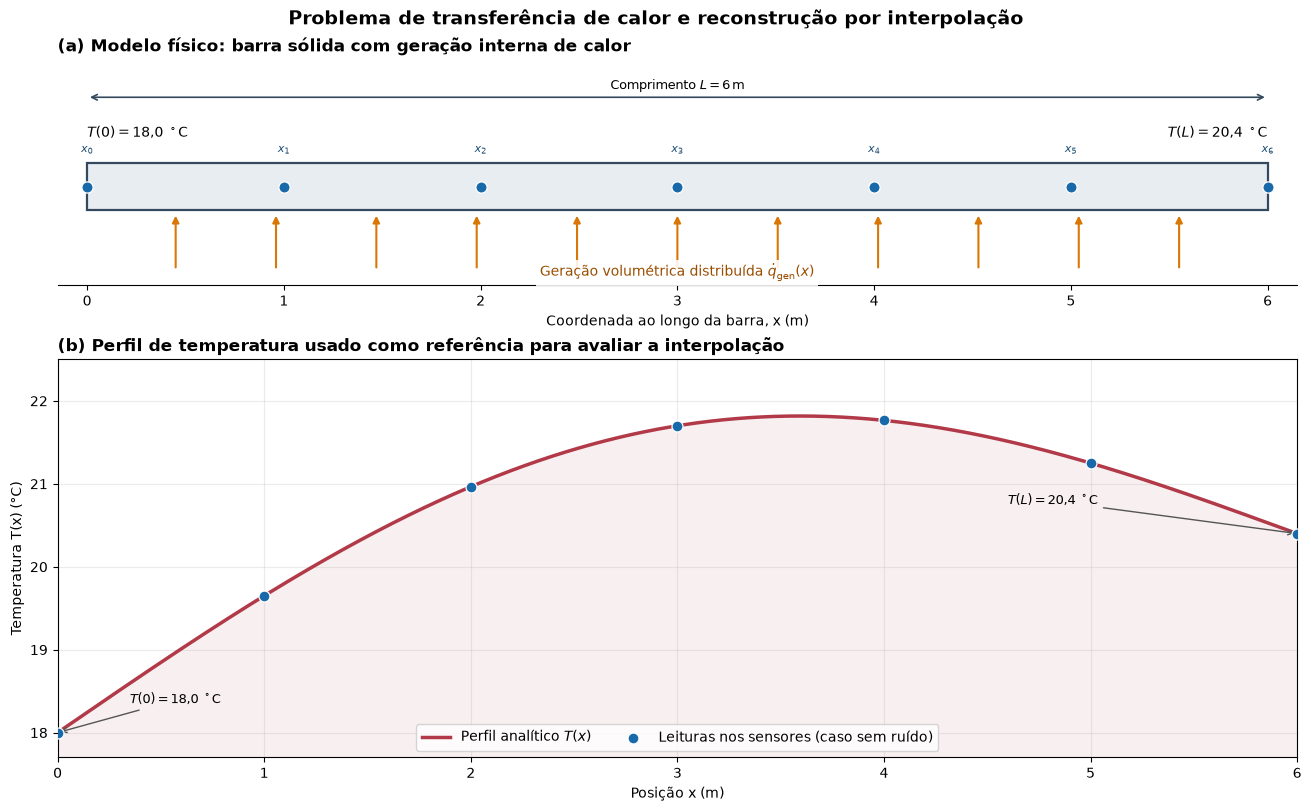

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [ ]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.

**Resultado:** Com 7 sensores exatos, o Lagrange global foi o melhor (erro máximo de cerca de 0,00009 °C), seguido da spline cúbica natural (0,0005 °C). A spline quadrática (0,024 °C) e a spline linear (0,082 °C) erraram bem mais. Nos gráficos de erro, todos os métodos têm erro zero nos sensores e o erro aparece entre eles. O maior erro do Lagrange fica perto das pontas da barra (x ≈ 0,3 m e x ≈ 5,7 m). Na spline linear o erro é sempre negativo, porque as retas ficam abaixo da curva, já que o perfil é curvado para baixo.

,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


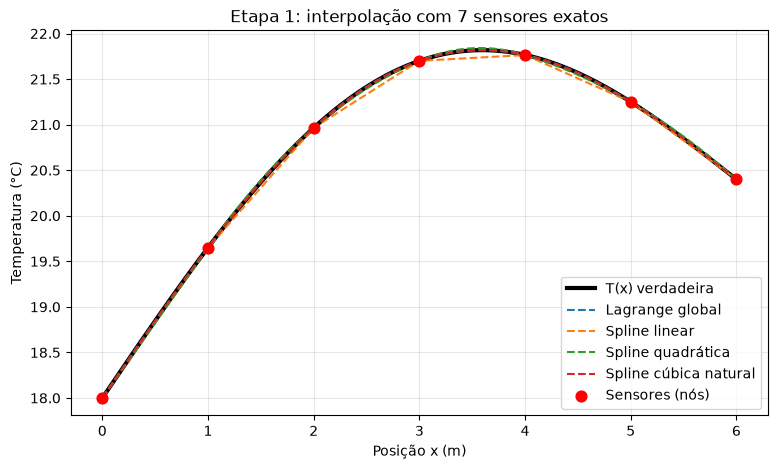

In [ ]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# Tabela de métricas na malha fina
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

# Os quatro métodos junto com a função verdadeira, marcando os nós
plt.figure()
plt.plot(x_fino, T_fino, color="black", linewidth=3, label="T(x) verdadeira")
for nome, metodo in metodos_7.items():
    plt.plot(x_fino, metodo(x_fino), "--", label=nome)
plt.scatter(x_nos_7, y_nos_7, color="red", s=60, zorder=5, label="Sensores (nós)")
plt.xlabel("Posição x (m)")
plt.ylabel("Temperatura (°C)")
plt.title("Etapa 1: interpolação com 7 sensores exatos")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

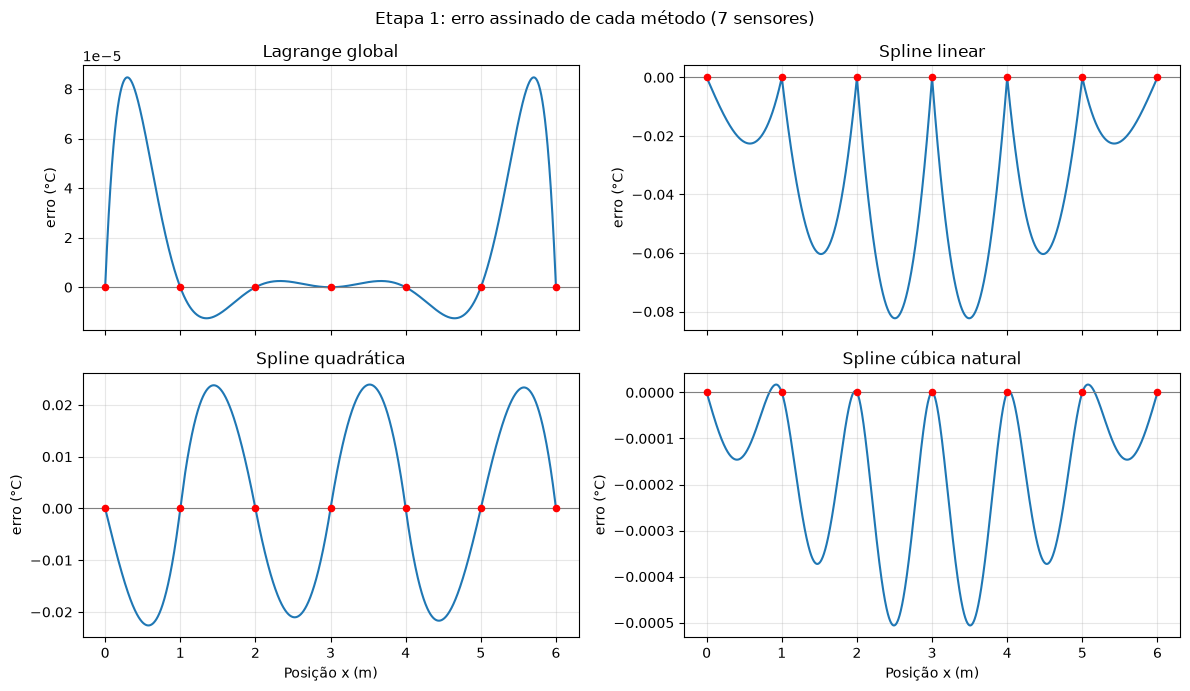

In [ ]:
# Gráfico dos erros assinados método a método
# erro = metodo(x_fino) - T_fino
fig, eixos = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (nome, metodo) in zip(eixos.flat, metodos_7.items()):
    erro = metodo(x_fino) - T_fino
    ax.plot(x_fino, erro)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.scatter(x_nos_7, np.zeros_like(x_nos_7), color="red", s=20, zorder=5)
    ax.set_title(nome)
    ax.set_ylabel("erro (°C)")
    ax.grid(True, alpha=0.3)
for ax in eixos[1]:
    ax.set_xlabel("Posição x (m)")
fig.suptitle("Etapa 1: erro assinado de cada método (7 sensores)")
plt.tight_layout()
plt.show()

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

**Resposta:** O erro caiu muito ao aumentar $N$, de cerca de $10^{-3}$ °C com 5 nós para $10^{-12}$ a $10^{-14}$ °C com 17 nós. Os nós de Chebyshev deram erro menor que os equiespaçados em todos os casos (com 17 nós, $1{,}4 \cdot 10^{-14}$ contra $2 \cdot 10^{-12}$ °C). Mesmo assim, não apareceu aquela oscilação forte nas pontas (fenômeno de Runge) com nós equiespaçados, porque o perfil é muito suave: é uma reta mais um seno, e o seno é muito bem aproximado por polinômios. Com uma função menos suave a diferença entre os dois tipos de nós seria bem maior. Então esse resultado vale para esse perfil, não dá para dizer que vai acontecer o mesmo com qualquer função.

In [ ]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

# Comparação para N = 5, 9, 13 e 17
# Para cada N, Lagrange com nós equiespaçados e com nós de Chebyshev.
resultados = []
for N in [5, 9, 13, 17]:
    for tipo in ["Equiespaçados", "Chebyshev"]:
        if tipo == "Equiespaçados":
            x_nos = np.linspace(x_min, x_max, N)
        else:
            x_nos = nos_chebyshev_lobatto(x_min, x_max, N)
        lagrange = BarycentricInterpolator(x_nos, temperatura_real(x_nos))
        erro = lagrange(x_fino) - T_fino
        resultados.append({"N": N, "Nós": tipo,
                           "Emax (°C)": np.max(np.abs(erro)),
                           "RMSE (°C)": np.sqrt(np.mean(erro**2))})

tabela_nos = pd.DataFrame(resultados)
display(tabela_nos)

,N,Nós,Emax (°C),RMSE (°C)
0,5,Equiespaçados,4.530257e-03,2.159567e-03
1,5,Chebyshev,2.326599e-03,1.532697e-03
2,9,Equiespaçados,1.043537e-06,3.438146e-07
3,9,Chebyshev,2.167582e-07,1.202332e-07
4,13,Equiespaçados,5.914202e-11,1.545427e-11
5,13,Chebyshev,3.623768e-12,1.932105e-12
6,17,Equiespaçados,1.989520e-12,2.445429e-13
7,17,Chebyshev,1.421085e-14,3.704811e-15


## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

**Resposta:** O erro do Lagrange (com os dois tipos de nós) cai muito rápido no começo e chega no limite da precisão do computador (cerca de $10^{-14}$ °C). Com Chebyshev ele fica nesse nível até $N = 40$, mas com nós equiespaçados o erro volta a subir depois de uns $N = 15$: com 40 nós o erro máximo já é de cerca de $10^{-5}$ °C. Isso é instabilidade numérica: com muitos nós igualmente espaçados os erros de arredondamento são amplificados. O erro da spline cúbica cai mais devagar (com 40 nós fica em torno de $3 \cdot 10^{-7}$ °C), mas cai sempre, sem voltar a subir. Com poucos nós ($N = 4$ a $6$) a spline foi a melhor de todas. E Chebyshev não ganhou sempre: com $N = 4$ ele errou mais que os nós equiespaçados (0,143 contra 0,109 °C), então a vantagem dele só aparece a partir de uns 5 ou 6 nós.

Sobre o custo, todos os tempos foram pequenos (milissegundos). A construção custou parecido nos três métodos, mas a avaliação do Lagrange foi várias vezes mais lenta que a da spline (na nossa execução, cerca de 1,7 ms contra 0,2 ms em média) e aumenta com $N$, porque cada ponto calculado usa todos os nós. Os tempos mudam um pouco cada vez que roda.

Então não existe um único método melhor para todo $N$: com poucos sensores a spline ganha, com $N$ médio o Lagrange é o mais preciso, e com muitos sensores equiespaçados o Lagrange fica instável.

,N,Método,Emax (°C),RMSE (°C),Construção (ms),Avaliação (ms)
0,4,Lagrange equiespaçado,1.090393e-01,6.829596e-02,0.4580,0.8155
1,4,Lagrange Chebyshev,1.429774e-01,8.094463e-02,0.4228,0.6608
2,4,Spline cúbica natural,1.017696e-02,4.786615e-03,1.5611,0.2265
3,8,Lagrange equiespaçado,6.095488e-05,2.251049e-05,0.6487,1.1290
4,8,Lagrange Chebyshev,3.375574e-05,1.937399e-05,0.7178,0.8057
5,8,Spline cúbica natural,2.776530e-04,1.263832e-04,1.1971,0.1447
6,12,Lagrange equiespaçado,6.565642e-09,1.840227e-09,0.9552,1.2994
7,12,Lagrange Chebyshev,1.100478e-09,6.334608e-10,0.8290,1.1004
8,12,Spline cúbica natural,4.420418e-05,2.000419e-05,1.1828,0.1903
9,20,Lagrange equiespaçado,1.289635e-11,1.187764e-12,1.1613,1.6313


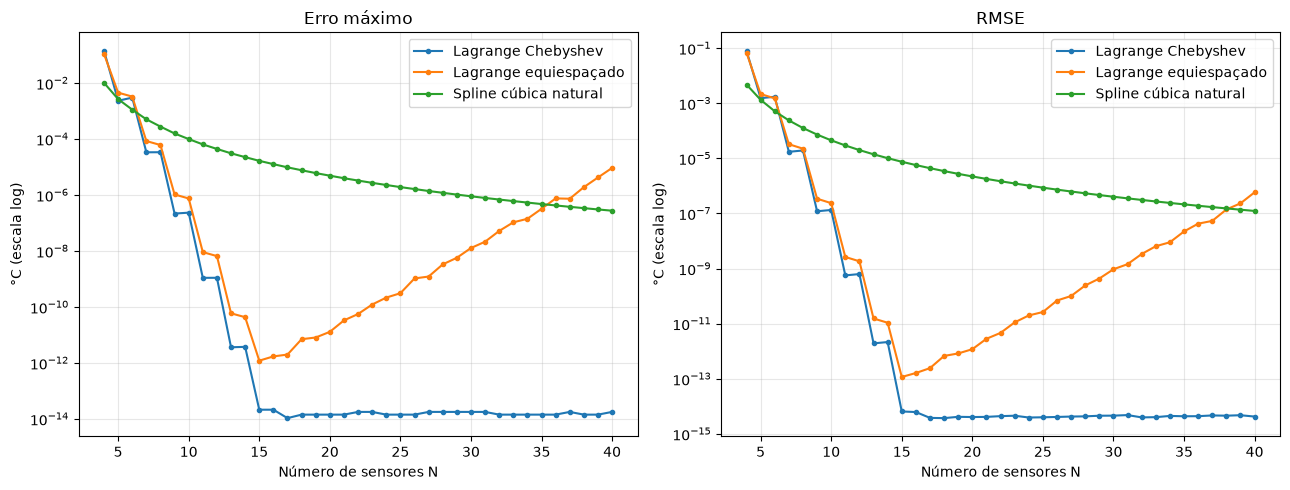

,Construção (ms),Avaliação (ms)
Método,,
Lagrange Chebyshev,1.180414,1.678949
Lagrange equiespaçado,1.196470,1.710970
Spline cúbica natural,1.225230,0.200530


In [ ]:
import time

resultados = []
for N in range(4, 41):
    x_eq = np.linspace(x_min, x_max, N)
    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    casos = {
        "Lagrange equiespaçado": (BarycentricInterpolator, x_eq),
        "Lagrange Chebyshev": (BarycentricInterpolator, x_ch),
        "Spline cúbica natural": (lambda x, y: CubicSpline(x, y, bc_type="natural"), x_eq),
    }
    for nome, (construir, x_nos) in casos.items():
        y_nos = temperatura_real(x_nos)
        t0 = time.perf_counter()
        interp = construir(x_nos, y_nos)       # construção
        t1 = time.perf_counter()
        T_aprox = interp(x_fino)               # avaliação na malha fina
        t2 = time.perf_counter()
        erro = T_aprox - T_fino
        resultados.append({"N": N, "Método": nome,
                           "Emax (°C)": np.max(np.abs(erro)),
                           "RMSE (°C)": np.sqrt(np.mean(erro**2)),
                           "Construção (ms)": (t1 - t0)*1000,
                           "Avaliação (ms)": (t2 - t1)*1000})

tabela_N = pd.DataFrame(resultados)

# Alguns valores de N para olhar a tabela
display(tabela_N[tabela_N["N"].isin([4, 8, 12, 20, 30, 40])].reset_index(drop=True))

# Erro máximo e RMSE em escala logarítmica
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for nome, grupo in tabela_N.groupby("Método"):
    eixos[0].semilogy(grupo["N"], grupo["Emax (°C)"], "o-", markersize=3, label=nome)
    eixos[1].semilogy(grupo["N"], grupo["RMSE (°C)"], "o-", markersize=3, label=nome)
eixos[0].set_title("Erro máximo")
eixos[1].set_title("RMSE")
for ax in eixos:
    ax.set_xlabel("Número de sensores N")
    ax.set_ylabel("°C (escala log)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

# Tempo médio de construção e de avaliação
display(tabela_N.groupby("Método")[["Construção (ms)", "Avaliação (ms)"]].mean())

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

O teste com ruído está no quadro de código logo abaixo.

**Resposta:**

- **Poucos sensores exatos:** para um perfil suave como esse, o Lagrange deu o menor erro (com 7 sensores, erro máximo de 0,00009 °C e RMSE de 0,00003 °C). Se desse para escolher onde colocar os sensores, colocaríamos nas posições de Chebyshev. Mas com só 4 a 6 sensores a spline cúbica foi melhor, então com muito poucos sensores escolheríamos a spline.
- **Mais sensores:** passaríamos para a spline cúbica, ou usaríamos o Lagrange só com nós de Chebyshev. Com muitos sensores igualmente espaçados o Lagrange fica instável (o erro voltou a subir depois de $N \approx 15$) e fica mais lento para calcular.
- **Sensores com ruído:** não usaríamos o Lagrange global. No teste com ruído de 0,05 °C e 17 sensores, o Lagrange teve RMSE de 3,2 °C e erro máximo de 16 °C, enquanto a spline cúbica teve RMSE de 0,046 °C e a linear 0,041 °C. Usaríamos uma spline e, se o ruído fosse grande, um ajuste por mínimos quadrados ou uma spline de suavização, que não obriga a curva a passar exatamente por cada leitura. Também ajuda fazer várias leituras em cada sensor e tirar a média.
- **Perto das extremidades:** é onde o Lagrange mais erra e onde o ruído mais atrapalha (no gráfico com ruído a curva dele sai do gráfico nas pontas). Colocaríamos sensores exatamente nas pontas, onde as temperaturas são conhecidas (18 °C e 20,4 °C), e mais sensores perto delas. E não faríamos extrapolação: dentro de [0, 6] m a interpolação funciona bem, mas fora desse intervalo nenhum desses métodos é confiável.
- **Limitações sem a temperatura verdadeira:** em campo não temos o $T(x)$ real, então não dá para calcular o erro máximo, o MAE e o RMSE como fizemos aqui. Uma saída é tirar um sensor, interpolar sem ele e comparar com a leitura dele, ou comparar métodos diferentes entre si. Também não temos garantia de que a temperatura real seja tão suave quanto o perfil usado (perdas de calor, fonte diferente ou sensor descalibrado mudam tudo), e o erro nunca fica menor que o ruído dos próprios sensores.

,N,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,7,Spline cúbica natural,0.087788,0.036720,0.044133
1,7,Lagrange global,0.124606,0.046788,0.057552
2,7,Spline linear,0.112878,0.049979,0.059048
3,7,Spline quadrática,0.133095,0.053228,0.064947
4,17,Spline linear,0.106409,0.032778,0.040709
5,17,Spline cúbica natural,0.109495,0.036929,0.045694
6,17,Spline quadrática,0.237604,0.078199,0.098123
7,17,Lagrange global,16.028475,1.093628,3.219274


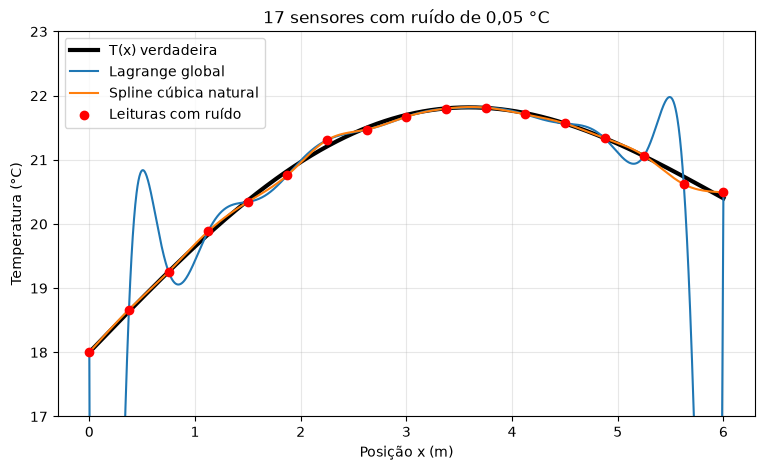

In [ ]:
# Teste com sensores com ruído (base para a recomendação da Etapa 4)
# Cada leitura recebe um erro aleatório com desvio padrão de 0,05 °C.
# Repetimos 200 vezes e tiramos a média das métricas.
rng = np.random.default_rng(42)
sigma = 0.05
repeticoes = 200

tabelas = []
for N in [7, 17]:
    x_nos = np.linspace(x_min, x_max, N)
    for r in range(repeticoes):
        y_ruido = temperatura_real(x_nos) + rng.normal(0, sigma, N)
        m = calcular_metricas(criar_metodos(x_nos, y_ruido), x_fino, T_fino)
        m["N"] = N
        tabelas.append(m)

tabela_ruido = (pd.concat(tabelas)
                .groupby(["N", "Método"]).mean()
                .sort_values(["N", "RMSE (°C)"]).reset_index())
display(tabela_ruido)

# Um exemplo com 17 sensores com ruído
x_nos = np.linspace(x_min, x_max, 17)
y_ruido = temperatura_real(x_nos) + rng.normal(0, sigma, 17)
metodos_ruido = criar_metodos(x_nos, y_ruido)
plt.figure()
plt.plot(x_fino, T_fino, color="black", linewidth=3, label="T(x) verdadeira")
plt.plot(x_fino, metodos_ruido["Lagrange global"](x_fino), label="Lagrange global")
plt.plot(x_fino, metodos_ruido["Spline cúbica natural"](x_fino), label="Spline cúbica natural")
plt.scatter(x_nos, y_ruido, color="red", zorder=5, label="Leituras com ruído")
plt.ylim(17, 23)
plt.xlabel("Posição x (m)")
plt.ylabel("Temperatura (°C)")
plt.title("17 sensores com ruído de 0,05 °C")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()